In [ ]:
# Imports and data directory
from pathlib import Path
import os
import numpy as np
import pandas as pd
from IPython.display import display

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Reproduce").is_dir())
from melon_pkg.plotting import *
from melon_pkg.preprocessing import load_features
DATA_ROOT = Path(os.environ.get("MELON_PUBLISHED_DATA", repo / "Published_Data_non_NASH"))
DATA = DATA_ROOT / "01_Mouse_E15_5"
assert DATA.is_dir(), "Place Published_Data_non_NASH beside Reproduce, or set MELON_PUBLISHED_DATA."


In [ ]:
# Parameters
config = {
    'epochs': 100,
    'batch_size': 2048,
    'embed_dim': 128,
    'training_seed': 42,
    'learning_rate': 0.001,
    'weight_decay': 1e-05,
    'temperature': 0.1,
    'training_spatial_k': 16,
    'export_spatial_k': 16,
    'augment_p': 0.8,
    'augmentations': ['gaussian_noise', 'feature_dropout', 'neighbor_mix'],
    'shuffle_batches': False,
    'clustering_seed': 2025,
    'target_clusters': 12,
    'clustering_neighbors': 10,
    'leiden_resolution': 1.0,
}
coords = read_indexed(DATA / "01_source_data/coords.csv")[["x", "y"]]
neighbor_grid = [8, 12, 14, 16, 18, 20, 24]
augmentation_grid = [0.0, 0.25, 0.5, 0.8, 1.0]
RESULTS = DATA / "05_Fig5_robustness"


In [ ]:
# Preprocessed RNA and ATAC
FEATURES = DATA / "02_model_inputs/MELON/features.npz"
barcodes, xy, features = load_features(FEATURES, ["RNA", "ATAC"])
coords = pd.DataFrame(xy, index=barcodes, columns=["x", "y"])


In [ ]:
# Train the parameter sweep
import torch
from torch import nn
from types import MethodType
import pytorch_lightning as pl
from melon_pkg.data import DualAugDataModule, SpatialOmicsAugmentations
from melon_pkg.model import SpotTokenAdapter
from melon_pkg.models.mmfusion import MMFusion
from melon_pkg.pl_modules.melon import MELONModel
from melon_pkg.utils import build_knn_mask
from melon_pkg.embedding import export_embedding
runs = {}
settings = [("neighbors", k, dict(config, training_spatial_k=k, export_spatial_k=k))
            for k in neighbor_grid]
settings += [("augmentation", p, dict(config, augment_p=p)) for p in augmentation_grid]
for sweep, value, parameters in settings:
    pl.seed_everything(parameters["training_seed"], workers=True)
    tensors = [torch.tensor(x, dtype=torch.float32) for x in features]
    xy = torch.as_tensor(coords.to_numpy(), dtype=torch.float32)
    mask, weights = build_knn_mask(xy, k=parameters["training_spatial_k"],
                                   include_self=True, return_weights=True, symmetric=True)
    augmentation = SpatialOmicsAugmentations
    aug = dict(augmentations=parameters["augmentations"], p=parameters["augment_p"])
    data = DualAugDataModule(
        mods_raw=tensors, coords=xy, neighbor_mask=mask, neighbor_weight=weights,
        augmentA=augmentation(**aug), augmentB=augmentation(**aug),
        batch_size=parameters["batch_size"], shuffle=parameters["shuffle_batches"],
        spot_tokenization=True,
    )

    dim = parameters["embed_dim"]
    encoder = MMFusion(
        encoders=[nn.Sequential(nn.Linear(x.shape[1], dim), nn.ReLU(), nn.Linear(dim, dim))
                  for x in tensors],
        input_adapters=[SpotTokenAdapter() for _ in tensors],
        embed_dim=dim, fusion="concat", pool="tokens", n_heads=8, n_layers=1,
    )
    model = MELONModel(
        encoder=encoder, projection=MELONModel._build_mlp(dim, 256, dim),
        optim_kwargs={"lr": parameters["learning_rate"], "weight_decay": parameters["weight_decay"]},
        loss_kwargs={"temperature": parameters["temperature"]},
        neighborhood_cfg={"hidden_dim": 64, "heads": 8, "dropout": 0.1,
                          "k_neighbors": parameters["training_spatial_k"], "include_self": True},
    )
    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), **self.optim_kwargs, betas=(0.9, 0.999))
    model.configure_optimizers = MethodType(configure_optimizers, model)

    trainer = pl.Trainer(max_epochs=parameters["epochs"], accelerator="cpu", devices=1,
                         logger=False, enable_checkpointing=False, deterministic=True)
    trainer.fit(model, datamodule=data)
    embedding = pd.DataFrame(
        export_embedding(model, tensors, xy, spatial_k=parameters["export_spatial_k"]),
        index=coords.index,
    )

    from melon_pkg.cli_cluster import leiden_clustering
    labels = leiden_clustering(
        embedding.to_numpy(), n_clusters=parameters["target_clusters"],
        n_neighbors=parameters["clustering_neighbors"], seed=parameters["clustering_seed"],
        resolution=parameters["leiden_resolution"],
    )
    domains = pd.Series(labels, index=embedding.index, name="MELON")
    runs[(sweep, value)] = (parameters, embedding, domains)
display({"neighborhood_settings": len(neighbor_grid), "augmentation_settings": len(augmentation_grid)})


In [ ]:
# Evaluate clustering
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
truth = read_indexed(DATA / "01_source_data/barcode_truth_k12.csv")["region_truth"]
metrics = pd.DataFrame([
    {"sweep": sweep, "value": value,
     "ARI": adjusted_rand_score(truth.loc[z.index], labels),
     "NMI": normalized_mutual_info_score(truth.loc[z.index], labels)}
    for (sweep, value), (_, z, labels) in runs.items()
])
display(metrics)


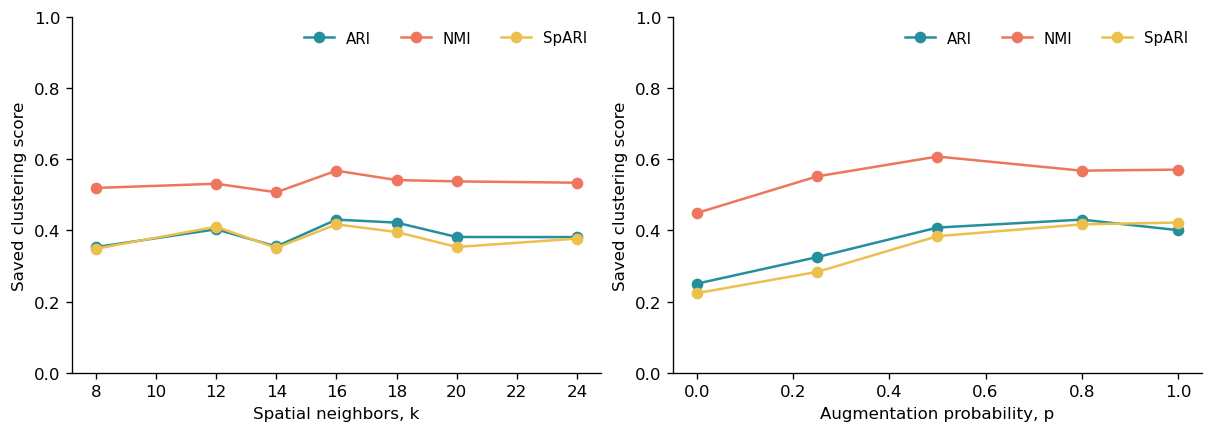

In [ ]:
# Sensitivity curves
neighbors = pd.read_csv(RESULTS / "neighbor_k_local_report_metrics.csv")
augmentation = pd.read_csv(RESULTS / "augment_p_report_metrics.csv")
assert set(neighbors.neighbor_k) == set(neighbor_grid)
assert set(augmentation.augment_p) == set(augmentation_grid)
show(sensitivity_panels(neighbors, augmentation))
